In [1]:
import os
import random
import itertools, time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models, regularizers

from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.metrics import accuracy_score, roc_auc_score, average_precision_score, balanced_accuracy_score

In [3]:
data = pd.read_csv("data/bank_data_train.csv")
test = pd.read_csv("data/bank_data_test.csv")

## Data Analysis

In [4]:
data_info = pd.DataFrame(index=data.columns, columns=['Dtype', 'NaN_count', 'NaN_percentage'])
for col in data.columns:
    col_nan_sum = data[col].isna().sum()
    data_info.loc[col] = (data[col].dtype, col_nan_sum, col_nan_sum/len(data[col])*100)

data_info

,Dtype,NaN_count,NaN_percentage
ID,int64,0,0.0
CR_PROD_CNT_IL,int64,0,0.0
AMOUNT_RUB_CLO_PRC,float64,38323,10.789437
PRC_ACCEPTS_A_EMAIL_LINK,float64,200027,56.315493
APP_REGISTR_RGN_CODE,float64,294640,82.952786
...,...,...,...
TURNOVER_DYNAMIC_CC_3M,float64,0,0.0
LDEAL_ACT_DAYS_PCT_TR,float64,261742,73.690701
LDEAL_ACT_DAYS_PCT_TR4,float64,261742,73.690701
LDEAL_ACT_DAYS_PCT_CURR,float64,261742,73.690701


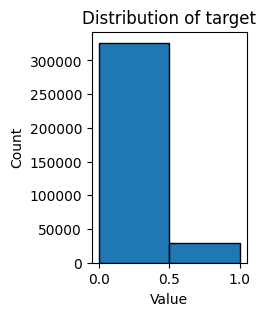

In [5]:
plt.figure(figsize=(2, 3))
plt.hist(data['TARGET'], bins=2, edgecolor='black')
plt.title('Distribution of target')
plt.xlabel('Value')
plt.ylabel('Count')
plt.show()

## Preprocessing

In [8]:
class LabelEncoderWithUnknown():
    def __init__(self):
        self.mapping_ = {}
        self.classes_ = None

    def fit(self, y):
        y = pd.Series(y)
        self.classes_ = np.sort(y.dropna().unique())
        self.mapping_ = {cat: i + 1 for i, cat in enumerate(self.classes_)}
        return self

    def transform(self, y):
        y = pd.Series(y)
        return y.map(self.mapping_).fillna(0).astype(int).values

    def fit_transform(self, y):
        return self.fit(y).transform(y)

def signed_log1p(x):
    return np.sign(x) * np.log1p(np.abs(x))

In [33]:
def test_data_preprocessing(data, cat_cols, cat_enc, **cols_by_types):
    data.loc[:, cat_cols] = data[cat_cols].fillna('missing_value')
    drop_cols = one_value_cols + ["TARGET", "ID"]

    X = data.drop(drop_cols, axis=1)

    X.loc[:, fill_na_zero_cols] = X[fill_na_zero_cols].fillna(0)

    for col in fill_na_zero_add_binary:
        X[f'{col}_ISNA'] = X[col].isna().astype('int8')
        X.loc[:, col] = X[col].fillna(0)

    for col in cat_cols:
        col_enc = cat_enc[col]
        X[col] = col_enc.transform(X[col])
        cat_enc[col] = col_enc

    scale_cols = list(set(X.columns) - set(cat_cols))

    X[scale_cols] = signed_log1p(X[scale_cols])

    return X

In [ ]:
def set_seed(seed=42):
    os.environ['PYTHONHASHSEED'] = str(seed)
    os.environ['TF_DETERMINISTIC_OPS'] = '1'

    random.seed(seed)
    np.random.seed(seed)
    tf.random.set_seed(seed)

set_seed(42)

In [7]:
fill_na_zero_cols = [
    "TRANS_AMOUNT_TENDENCY3M", "TRANS_CNT_TENDENCY3M",
    "TRANS_COUNT_ATM_PRC", "TRANS_COUNT_NAS_PRC", "TRANS_COUNT_SUP_PRC",

    "SUM_TRAN_ATM_TENDENCY1M", "SUM_TRAN_ATM_TENDENCY3M",
    "SUM_TRAN_AUT_TENDENCY1M", "SUM_TRAN_AUT_TENDENCY3M",
    "SUM_TRAN_CLO_TENDENCY1M", "SUM_TRAN_CLO_TENDENCY3M",
    "SUM_TRAN_MED_TENDENCY1M", "SUM_TRAN_MED_TENDENCY3M",
    "SUM_TRAN_SUP_TENDENCY1M", "SUM_TRAN_SUP_TENDENCY3M",

    "CNT_TRAN_ATM_TENDENCY1M", "CNT_TRAN_ATM_TENDENCY3M",
    "CNT_TRAN_AUT_TENDENCY1M", "CNT_TRAN_AUT_TENDENCY3M",
    "CNT_TRAN_CLO_TENDENCY1M", "CNT_TRAN_CLO_TENDENCY3M",
    "CNT_TRAN_MED_TENDENCY1M", "CNT_TRAN_MED_TENDENCY3M",
    "CNT_TRAN_SUP_TENDENCY1M", "CNT_TRAN_SUP_TENDENCY3M",

    "AMOUNT_RUB_ATM_PRC", "AMOUNT_RUB_CLO_PRC", "AMOUNT_RUB_NAS_PRC", "AMOUNT_RUB_SUP_PRC"]

fill_na_zero_add_binary = [
    "LDEAL_AMT_MONTH",
    "LDEAL_TENOR_MIN",
    "LDEAL_TENOR_MAX",
    "MAX_PCLOSE_DATE",
    "AVG_PCT_MONTH_TO_PCLOSE",
    "AVG_PCT_DEBT_TO_DEAL_AMT",

    "MED_DEBT_PRC_YQZ",         "MED_DEBT_PRC_YWZ",
    "LDEAL_USED_AMT_AVG_YQZ",   "LDEAL_USED_AMT_AVG_YWZ",
    "LDEAL_DELINQ_PER_MAXYQZ",  "LDEAL_DELINQ_PER_MAXYWZ",
    "DEAL_YQZ_IR_MIN",          "DEAL_YQZ_IR_MAX",
    "DEAL_YWZ_IR_MIN",          "DEAL_YWZ_IR_MAX",

    "LDEAL_YQZ_CHRG",
    "LDEAL_YQZ_COM",
    "LDEAL_YQZ_PC",

    "LDEAL_ACT_DAYS_PCT_CURR",
    "LDEAL_ACT_DAYS_PCT_AAVG",
    "LDEAL_ACT_DAYS_ACC_PCT_AVG",
    "LDEAL_ACT_DAYS_PCT_TR",
    "LDEAL_ACT_DAYS_PCT_TR3",
    "LDEAL_ACT_DAYS_PCT_TR4",

    "LDEAL_GRACE_DAYS_PCT_MED",
    "DEAL_GRACE_DAYS_ACC_AVG",
    "DEAL_GRACE_DAYS_ACC_MAX",
    "DEAL_GRACE_DAYS_ACC_S1X1",

    "APP_REGISTR_RGN_CODE",
    "CLNT_SALARY_VALUE"]

one_value_cols = ['PRC_ACCEPTS_A_AMOBILE',
                'PRC_ACCEPTS_A_ATM',
                'PRC_ACCEPTS_A_EMAIL_LINK',
                'PRC_ACCEPTS_A_MTP',
                'PRC_ACCEPTS_A_POS',
                'PRC_ACCEPTS_A_TK',
                'PRC_ACCEPTS_MTP',
                'PRC_ACCEPTS_TK',
                'CNT_ACCEPTS_TK',
                'CNT_ACCEPTS_MTP']

In [10]:
data = data.drop_duplicates()

cat_cols = data_info[data_info['Dtype'] == 'object'].index
data.loc[:, cat_cols] = data[cat_cols].fillna('missing_value')

In [11]:
drop_cols = one_value_cols + ["TARGET", "ID"]

X = data.drop(drop_cols, axis=1)
y = data["TARGET"]
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [12]:
X_train.loc[:, fill_na_zero_cols] = X_train[fill_na_zero_cols].fillna(0)
X_val.loc[:, fill_na_zero_cols] = X_val[fill_na_zero_cols].fillna(0)

In [13]:
for col in fill_na_zero_add_binary:
    X_train[f'{col}_ISNA'] = X_train[col].isna().astype('int8')
    X_val[f'{col}_ISNA'] = X_val[col].isna().astype('int8')
    X_train.loc[:, col] = X_train[col].fillna(0)
    X_val.loc[:, col] = X_val[col].fillna(0)

In [14]:
cat_enc = {}
for col in cat_cols:
    col_enc = LabelEncoderWithUnknown()
    X_train[col] = col_enc.fit_transform(X_train[col])
    X_val[col] = col_enc.transform(X_val[col])
    cat_enc[col] = col_enc

In [15]:
def signed_log1p(x):
    return np.sign(x) * np.log1p(np.abs(x))

scale_cols = list(set(X_train.columns) - set(cat_cols))

X_train[scale_cols] = signed_log1p(X_train[scale_cols])
X_val[scale_cols] = signed_log1p(X_val[scale_cols])

In [34]:
cols_by_types = {'fill_na_zero_cols': fill_na_zero_cols,
                 'fill_na_zero_add_binary': fill_na_zero_add_binary,
                 'one_value_cols':one_value_cols}

X_test = test_data_preprocessing(test, cat_cols, cat_enc, **cols_by_types)

## Models

In [ ]:
results = pd.DataFrame(columns=['Accuracy', 'ROC-AUC', 'Avg Precis'])

In [ ]:
def add_to_res(preds, probas, val):
    acc = accuracy_score(val, preds)
    roc_auc = roc_auc_score(val, probas)
    ap = average_precision_score(val, probas)

    return [acc, roc_auc, ap]

### Baseline

#### Naive Bayes

In [ ]:
naive_bayes_pred = np.full(len(y_val), np.round(y_train.mean()))
results.loc['Naive Bayes (Baseline)'] = add_to_res(naive_bayes_pred, naive_bayes_pred, y_val)
results.loc['Naive Bayes (Baseline)']

,Naive Bayes (Baseline)
Accuracy,0.918565
ROC-AUC,0.500000
Avg Precis,0.081435


#### Random Forest

In [ ]:
forest = RandomForestClassifier(n_estimators=100, min_samples_leaf=5, random_state=42)
forest.fit(X_train, y_train)
forest_preds = forest.predict(X_val)
forest_probas = forest.predict_proba(X_val)
results.loc['Random Forest (Baseline)'] = add_to_res(forest_preds, forest_probas[:, 1], y_val)
results.loc['Random Forest (Baseline)']

,Random Forest (Baseline)
Accuracy,0.919494
ROC-AUC,0.834838
Avg Precis,0.322340


In [ ]:
kfold = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
metrics = np.zeros(3)
for i, (train_index, val_index) in enumerate(kfold.split(X, y)):
    forest.fit(X.iloc[train_index], y.iloc[train_index])
    forest_preds = forest.predict(X.iloc[val_index])
    forest_probas = forest.predict_proba(X.iloc[val_index])
    metrics += add_to_res(forest_preds, forest_probas[:, 1], y.iloc[val_index])

results.loc['Random Forest (Baseline) CV'] = metrics / 5
results.loc['Random Forest (Baseline) CV']

,Random Forest (Baseline) CV
Accuracy,0.919440
ROC-AUC,0.835989
Avg Precis,0.326740


In [ ]:
params = {
    'n_estimators': [75, 100, 125],
    'min_samples_leaf': [3, 5, 7],
    'max_depth': [None, 25, 15],
    'n_jobs': [-1],
    'random_state': [42]
}

grid_search = GridSearchCV(forest, params, scoring='roc_auc', n_jobs=-1,
                           verbose=1, cv=kfold)

grid_search.fit(X, y)
print(grid_search.best_params_)

Fitting 5 folds for each of 27 candidates, totalling 135 fits


/usr/local/lib/python3.13/dist-packages/joblib/externals/loky/process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


{'max_depth': None, 'min_samples_leaf': 7, 'n_estimators': 125, 'n_jobs': -1, 'random_state': 42}


In [ ]:
random_forest_best_params = {
    'max_depth': None,
    'min_samples_leaf': 7,
    'n_estimators': 125,
    'n_jobs': -1,
    'random_state': 42
}

metrics = np.zeros(3)
forest = RandomForestClassifier(**random_forest_best_params)
for i, (train_index, val_index) in enumerate(kfold.split(X, y)):
    forest.fit(X.iloc[train_index], y.iloc[train_index])
    forest_preds = forest.predict(X.iloc[val_index])
    forest_probas = forest.predict_proba(X.iloc[val_index])
    metrics += add_to_res(forest_preds, forest_probas[:, 1], y.iloc[val_index])

results.loc['Random Forest (Baseline) CV Best'] = metrics / 5
results.loc['Random Forest (Baseline) CV Best']

,Random Forest (Baseline) CV Best
Accuracy,0.919288
ROC-AUC,0.837178
Avg Precis,0.326998


### MLP

#### Sklearn

In [ ]:
skl_mlp_params = {
    'hidden_layer_sizes': (128, 64),
    'activation': 'relu',
    'solver': 'adam',
    'learning_rate': 'constant',
    'max_iter': 200,
    'random_state': 42
}

skl_mlp = MLPClassifier(**skl_mlp_params)

In [ ]:
%%time

skl_mlp.fit(X_train, y_train)
skl_mlp_preds = skl_mlp.predict(X_val)
skl_mlp_probas = skl_mlp.predict_proba(X_val)
results.loc['Sklearn MLP'] = add_to_res(skl_mlp_preds, skl_mlp_probas[:, 1], y_val)
results.loc['Sklearn MLP']

CPU times: user 15min 16s, sys: 842 ms, total: 15min 17s
Wall time: 8min 23s


,Sklearn MLP
Accuracy,0.917931
ROC-AUC,0.776493
Avg Precis,0.242852


In [ ]:
params = {
    'hidden_layer_sizes': [(128, 64)],
    'activation': ['relu', 'logistic', 'tanh'],
    'solver': ['sgd', 'adam'],
    'learning_rate': ['constant', 'invscaling', 'adaptive'],
    'random_state': [42]
}

kfold = StratifiedKFold(n_splits=2, shuffle=True, random_state=42)
grid_search = GridSearchCV(skl_mlp, params, scoring='roc_auc', n_jobs=-1,
                           verbose=1, cv=kfold)

grid_search.fit(X, y)
print(grid_search.best_params_)

Fitting 2 folds for each of 18 candidates, totalling 36 fits
{'activation': 'tanh', 'hidden_layer_sizes': (128, 64), 'learning_rate': 'adaptive', 'random_state': 42, 'solver': 'sgd'}


In [ ]:
skl_mlp_best_params = {
    'activation': 'tanh',
    'hidden_layer_sizes': (128, 64),
    'learning_rate': 'adaptive',
    'random_state': 42,
    'max_iter': 500,
    'solver': 'sgd'
}

skl_mlp = MLPClassifier(**skl_mlp_best_params)

kfold = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
metrics = np.zeros(3)
for i, (train_index, val_index) in enumerate(kfold.split(X, y)):
    skl_mlp.fit(X.iloc[train_index], y.iloc[train_index])
    skl_mlp_preds = skl_mlp.predict(X.iloc[val_index])
    skl_mlp_probas = skl_mlp.predict_proba(X.iloc[val_index])
    metrics += add_to_res(skl_mlp_preds, skl_mlp_probas[:, 1], y.iloc[val_index])

results.loc['Sklearn MLP CV Best'] = metrics / 5
results.loc['Sklearn MLP CV Best']

,Sklearn MLP CV Best
Accuracy,0.918565
ROC-AUC,0.478604
Avg Precis,0.081458


#### Keras

In [21]:
def make_callbacks():
    return [
        keras.callbacks.EarlyStopping(monitor="val_auc", mode="max",
                                      patience=8, restore_best_weights=True),
        keras.callbacks.ReduceLROnPlateau(monitor="val_auc", mode="max",
                                          factor=0.5, patience=3),
    ]

def build_model(X):
    norm = layers.Normalization()
    norm.adapt(X.to_numpy())

    keras_model = models.Sequential([
        layers.Input(shape=(X.shape[1],)),
        norm,
        layers.Dense(256, activation='relu', kernel_regularizer=regularizers.l2(1e-4)),
        layers.Dropout(0.3),
        layers.Dense(128, activation='relu', kernel_regularizer=regularizers.l2(1e-4)),
        layers.Dropout(0.3),
        layers.Dense(64, activation='relu'),
        layers.Dense(1, activation='sigmoid')
    ])

    keras_model.compile(
        optimizer=tf.keras.optimizers.AdamW(learning_rate=1e-3, weight_decay=1e-4),
        loss='binary_crossentropy',
        metrics=['accuracy',
                 keras.metrics.AUC(name='auc'),
                 keras.metrics.AUC(curve='PR', name='avg_precision')]
    )

    return keras_model

In [22]:
def plot_res(history):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    axes[0].plot(history.history['loss'], label='train')
    axes[0].plot(history.history['val_loss'], label='val')
    axes[0].set_title('Loss')
    axes[0].set_xlabel('Epoch')
    axes[0].legend()

    axes[1].plot(history.history['auc'], label='train')
    axes[1].plot(history.history['val_auc'], label='val')
    axes[1].set_title('AUC')
    axes[1].set_xlabel('Epoch')
    axes[1].legend()

    plt.tight_layout()
    plt.show()

##### Keras Baseline

In [ ]:
norm = layers.Normalization()
norm.adapt(X_train.to_numpy())

keras_model = models.Sequential([
    layers.Input(shape=(X_train.shape[1],)),
    norm,
    layers.Dense(128, activation='relu', kernel_regularizer=regularizers.l2(1e-4)),
    layers.Dropout(0.3),
    layers.Dense(64, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(32, activation='relu'),
    layers.Dense(1, activation='sigmoid')
])

keras_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss='binary_crossentropy',
    metrics=['accuracy',
            keras.metrics.AUC(name='auc'),
            keras.metrics.AUC(curve='PR', name='avg_precision')]
)

keras_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ normalization (Normalization)   │ (None, 135)            │           271 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        17,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 28,048 (109.57 KB)

 Trainable params: 27,777 (108.50 KB)

 Non-trainable params: 271 (1.06 KB)

In [ ]:
history = keras_model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=30,
    batch_size=64,
    class_weight={1: 6},
    verbose=1
)

Epoch 1/30
4440/4440 ━━━━━━━━━━━━━━━━━━━━ 12s 2ms/step - accuracy: 0.8107 - auc: 0.7476 - avg_precision: 0.1944 - loss: 0.7944 - val_accuracy: 0.8261 - val_auc: 0.7974 - val_avg_precision: 0.2582 - val_loss: 0.4116
Epoch 2/30
4440/4440 ━━━━━━━━━━━━━━━━━━━━ 20s 2ms/step - accuracy: 0.8011 - auc: 0.7928 - avg_precision: 0.2385 - loss: 0.7377 - val_accuracy: 0.8141 - val_auc: 0.8042 - val_avg_precision: 0.2641 - val_loss: 0.4003
Epoch 3/30
4440/4440 ━━━━━━━━━━━━━━━━━━━━ 10s 2ms/step - accuracy: 0.8025 - auc: 0.8027 - avg_precision: 0.2518 - loss: 0.7257 - val_accuracy: 0.7982 - val_auc: 0.8145 - val_avg_precision: 0.2809 - val_loss: 0.4026
Epoch 4/30
4440/4440 ━━━━━━━━━━━━━━━━━━━━ 10s 2ms/step - accuracy: 0.8019 - auc: 0.8094 - avg_precision: 0.2615 - loss: 0.7163 - val_accuracy: 0.8119 - val_auc: 0.8179 - val_avg_precision: 0.2817 - val_loss: 0.4007
Epoch 5/30
4440/4440 ━━━━━━━━━━━━━━━━━━━━ 11s 3ms/step - accuracy: 0.8008 - auc: 0.8130 - avg_precision: 0.2659 - loss: 0.7118 - val_accurac

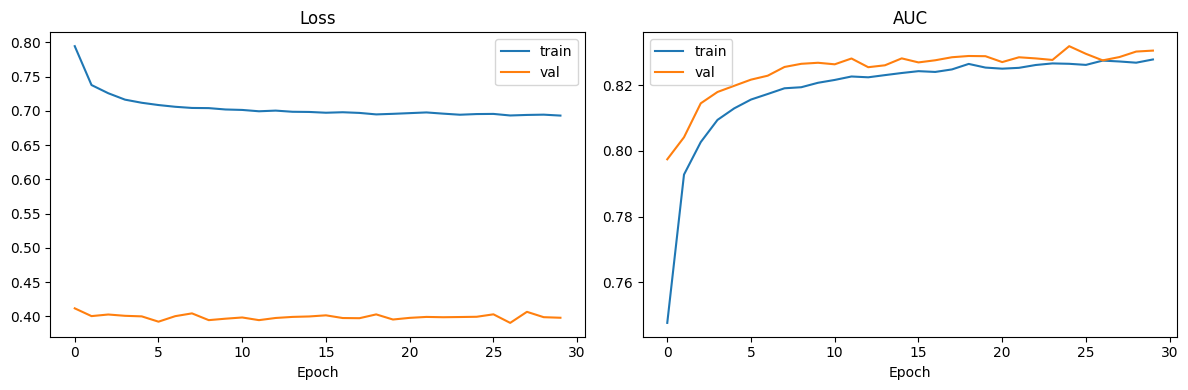

In [ ]:
plot_res(history)

In [ ]:
final_metrics = np.array([
    history.history['val_accuracy'][-1],
    history.history['val_auc'][-1],
    history.history['val_avg_precision'][-1]
])

results.loc['Keras Baseline'] = final_metrics

##### Feature selection

In [ ]:
def keras_auc(estimator, X, y):
    probs = estimator.predict(X, verbose=0).ravel()
    return roc_auc_score(y, probs)

In [ ]:
result = permutation_importance(
    keras_model,
    X_val, y_val,
    scoring=keras_auc,
    n_repeats=10,
    random_state=42,
)

In [ ]:
feature_imps = pd.DataFrame({'mean': result.importances_mean,
                             'std': result.importances_std},
                            index=X_val.columns)

In [ ]:
feature_imps.to_csv("data/feature_importances.csv")

In [26]:
feature_imps = pd.read_csv("data/feature_importances.csv", index_col='Unnamed: 0')

In [27]:
good_features = feature_imps[feature_imps['mean'] > 0].index

##### Updated

In [ ]:
set_seed(42)

keras_model = build_model(X_train[good_features])

keras_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ normalization_1 (Normalization) │ (None, 117)            │           235 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 256)            │        30,208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 71,660 (279.93 KB)

 Trainable params: 71,425 (279.00 KB)

 Non-trainable params: 235 (944.00 B)

In [ ]:
history = keras_model.fit(
    X_train[good_features], y_train,
    validation_data=(X_val[good_features], y_val),
    epochs=30,
    batch_size=64,
    class_weight={1: 6},
    verbose=1,
    callbacks=make_callbacks()
)

Epoch 1/30
4440/4440 ━━━━━━━━━━━━━━━━━━━━ 23s 5ms/step - accuracy: 0.8057 - auc: 0.7650 - avg_precision: 0.2120 - loss: 0.7935 - val_accuracy: 0.8257 - val_auc: 0.8025 - val_avg_precision: 0.2624 - val_loss: 0.4094 - learning_rate: 0.0010
Epoch 2/30
4440/4440 ━━━━━━━━━━━━━━━━━━━━ 16s 4ms/step - accuracy: 0.8012 - auc: 0.8009 - avg_precision: 0.2493 - loss: 0.7416 - val_accuracy: 0.8157 - val_auc: 0.8124 - val_avg_precision: 0.2750 - val_loss: 0.4073 - learning_rate: 0.0010
Epoch 3/30
4440/4440 ━━━━━━━━━━━━━━━━━━━━ 47s 10ms/step - accuracy: 0.8055 - auc: 0.8092 - avg_precision: 0.2605 - loss: 0.7288 - val_accuracy: 0.8185 - val_auc: 0.8170 - val_avg_precision: 0.2788 - val_loss: 0.4067 - learning_rate: 0.0010
Epoch 4/30
4440/4440 ━━━━━━━━━━━━━━━━━━━━ 18s 4ms/step - accuracy: 0.8073 - auc: 0.8138 - avg_precision: 0.2660 - loss: 0.7217 - val_accuracy: 0.8053 - val_auc: 0.8198 - val_avg_precision: 0.2813 - val_loss: 0.4154 - learning_rate: 0.0010
Epoch 5/30
4440/4440 ━━━━━━━━━━━━━━━━━━━━ 1

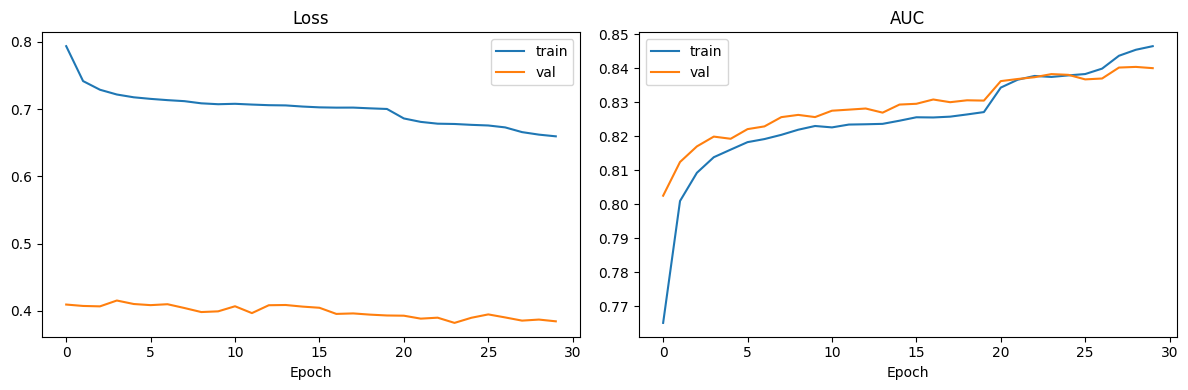

In [ ]:
plot_res(history)

In [ ]:
final_metrics = np.array([
    history.history['val_accuracy'][-1],
    history.history['val_auc'][-1],
    history.history['val_avg_precision'][-1]
])

results.loc['Keras Feature Selected'] = final_metrics

In [ ]:
val_preds = []
for seed in range(10):
    set_seed(seed)
    m = build_model(X_train[good_features])
    m.fit(
        X_train[good_features], y_train,
        validation_data=(X_val[good_features], y_val),
        epochs=30,
        batch_size=64,
        class_weight={1: 6},
        verbose=0,
        callbacks=make_callbacks())

    p = m.predict(X_val[good_features], batch_size=64, verbose=0).ravel()
    val_preds.append(p)
    print(f"seed {seed}: AUC {roc_auc_score(y_val, p):.4f}")

print("ensemble AUC:", roc_auc_score(y_val, np.mean(val_preds, axis=0)))

seed 0: AUC 0.8405
seed 1: AUC 0.8412
seed 2: AUC 0.8412
seed 3: AUC 0.8385
seed 4: AUC 0.8407
seed 5: AUC 0.8384
seed 6: AUC 0.8426
seed 7: AUC 0.8413
seed 8: AUC 0.8408
seed 9: AUC 0.8422
ensemble AUC: 0.8445289944579917


##### Best params

In [23]:
def build_model(X, units=256, depth=3, shrink=0.5, dropout=0.3, l2=1e-4,
                lr=1e-3, wd=1e-4, noise=0.0, activation="relu", **_ignored):
    X = np.asarray(X, dtype="float32")
    norm = layers.Normalization()
    norm.adapt(X)

    stack = [layers.Input(shape=(X.shape[1],)), norm]
    if noise > 0:
        stack.append(layers.GaussianNoise(noise))
    width = units
    for _ in range(depth):
        stack += [layers.Dense(max(int(width), 8), activation=activation,
                               kernel_regularizer=regularizers.l2(l2)),
                  layers.Dropout(dropout)]
        width *= shrink
    stack.append(layers.Dense(1, activation="sigmoid"))

    model = keras.Sequential(stack)
    model.compile(optimizer=keras.optimizers.AdamW(learning_rate=lr, weight_decay=wd),
                  loss="binary_crossentropy",
                  metrics=['accuracy',
                            keras.metrics.AUC(name='auc'),
                            keras.metrics.AUC(curve='PR', name='avg_precision')])
    return model


def make_callbacks(patience=5):
    return [
        keras.callbacks.EarlyStopping(monitor="val_auc", mode="max", patience=patience,
                                      restore_best_weights=True),
        keras.callbacks.ReduceLROnPlateau(monitor="val_auc", mode="max",
                                          factor=0.5, patience=2),
    ]


In [ ]:
SPACE = {
    "units":      [64, 128, 256, 512],
    "depth":      [2, 3, 4],
    "shrink":     [0.5, 0.75, 1.0],
    "dropout":    [0.2, 0.3, 0.4, 0.5],
    "l2":         [0.0, 1e-5, 1e-4, 1e-3],
    "lr":         [3e-4, 5e-4, 1e-3, 2e-3],
    "wd":         [0.0, 1e-4, 1e-3, 1e-2],
    "noise":      [0.0, 0.05, 0.1, 0.2],
    "activation": ["relu", "swish"],
    "batch_size": [256, 512, 1024],
    "pos_weight": [1.0, 3.0, 6.0, 11.0],
}


def sample_configs(space, n, seed=0):
    rng = np.random.default_rng(seed)
    seen, out = set(), []
    while len(out) < n:
        cfg = {k: v[rng.integers(len(v))] for k, v in space.items()}
        key = tuple(cfg.values())
        if key not in seen:
            seen.add(key)
            out.append(cfg)
    return out


def grid_configs(space):
    keys = list(space)
    return [dict(zip(keys, vals)) for vals in itertools.product(*space.values())]


def stratified_folds(y, k, seed=0):
    rng = np.random.default_rng(seed)
    fold_of = np.empty(len(y), dtype=int)
    for cls in np.unique(y):
        idx = np.where(y == cls)[0]
        rng.shuffle(idx)
        fold_of[idx] = np.arange(len(idx)) % k
    return [(np.where(fold_of != f)[0], np.where(fold_of == f)[0]) for f in range(k)]


def evaluate(cfg, X, y, folds, max_epochs=30, seed=0):
    scores, epochs = [], []
    for f, (tr, ho) in enumerate(folds):
        keras.backend.clear_session()
        set_seed(seed + f)
        m = build_model(X[tr], **cfg)
        h = m.fit(X[tr], y[tr], validation_data=(X[ho], y[ho]),
                  epochs=max_epochs, batch_size=cfg["batch_size"],
                  class_weight={0: 1.0, 1: cfg["pos_weight"]},
                  callbacks=make_callbacks(), verbose=0)
        scores.append(max(h.history["val_auc"]))
        epochs.append(int(np.argmax(h.history["val_auc"])) + 1)
    return float(np.mean(scores)), float(np.std(scores)), float(np.mean(epochs))

In [ ]:
Xtr = np.asarray(X_train[good_features], dtype="float32")
ytr = np.asarray(y_train, dtype="float32")

N_STAGE1, TOP_K = 40, 8
folds_all = stratified_folds(ytr, k=3, seed=123)

rows = []
t0 = time.time()
for i, cfg in enumerate(sample_configs(SPACE, N_STAGE1, seed=0)):
    auc, _, ep = evaluate(cfg, Xtr, ytr, folds_all[:1])
    rows.append({**cfg, "auc_s1": auc, "best_epoch": ep})
    print(f"[{i+1}/{N_STAGE1}] {auc:.4f}  ep{ep:>2}  {time.time()-t0:5.0f}s  {cfg}")

stage1 = pd.DataFrame(rows).sort_values("auc_s1", ascending=False).reset_index(drop=True)
print(stage1.head(10).to_string())

[1/40] 0.8393  ep29.0    524s  {'units': 512, 'depth': 3, 'shrink': 0.75, 'dropout': 0.3, 'l2': 1e-05, 'lr': 0.0003, 'wd': 0.0, 'noise': 0.0, 'activation': 'relu', 'batch_size': 1024, 'pos_weight': 6.0}
[2/40] 0.8383  ep30.0   1382s  {'units': 512, 'depth': 3, 'shrink': 0.75, 'dropout': 0.5, 'l2': 0.0001, 'lr': 0.001, 'wd': 0.001, 'noise': 0.1, 'activation': 'swish', 'batch_size': 256, 'pos_weight': 11.0}
[3/40] 0.8221  ep30.0   1670s  {'units': 256, 'depth': 2, 'shrink': 0.75, 'dropout': 0.5, 'l2': 0.0001, 'lr': 0.0003, 'wd': 0.01, 'noise': 0.1, 'activation': 'swish', 'batch_size': 256, 'pos_weight': 1.0}
[4/40] 0.8393  ep28.0   2179s  {'units': 512, 'depth': 2, 'shrink': 0.75, 'dropout': 0.2, 'l2': 1e-05, 'lr': 0.0005, 'wd': 0.0001, 'noise': 0.05, 'activation': 'relu', 'batch_size': 256, 'pos_weight': 1.0}
[5/40] 0.8312  ep30.0   2277s  {'units': 64, 'depth': 4, 'shrink': 0.75, 'dropout': 0.4, 'l2': 1e-05, 'lr': 0.001, 'wd': 0.01, 'noise': 0.05, 'activation': 'relu', 'batch_size': 10

In [ ]:
finalists = stage1.head(TOP_K)
param_names = list(SPACE)
res2 = []
for i, row in finalists.iterrows():
    cfg = {k: row[k].item() if hasattr(row[k], "item") else row[k] for k in param_names}
    mean, std, ep = evaluate(cfg, Xtr, ytr, folds_all, seed=100)
    res2.append({**cfg, "auc_cv": mean, "auc_std": std, "best_epoch": ep})
    print(f"finalist {i}: CV AUC {mean:.4f} +/- {std:.4f}")

stage2 = pd.DataFrame(res2).sort_values("auc_cv", ascending=False).reset_index(drop=True)
print(stage2.to_string())
best_cfg = {k: stage2.loc[0, k].item() if hasattr(stage2.loc[0, k], "item") else stage2.loc[0, k]
            for k in param_names}
print("BEST:", best_cfg)

finalist 0: CV AUC 0.8414 +/- 0.0009
finalist 1: CV AUC 0.8385 +/- 0.0015
finalist 2: CV AUC 0.8394 +/- 0.0008
finalist 3: CV AUC 0.8389 +/- 0.0003
finalist 4: CV AUC 0.8387 +/- 0.0010
finalist 5: CV AUC 0.8384 +/- 0.0011
finalist 6: CV AUC 0.8389 +/- 0.0016
finalist 7: CV AUC 0.8366 +/- 0.0017
   units  depth  shrink  dropout       l2      lr      wd  noise activation  batch_size  pos_weight    auc_cv   auc_std  best_epoch
0    256      2    1.00      0.4  0.00010  0.0020  0.0100   0.00       relu        1024         3.0  0.841412  0.000949   29.666667
1    512      4    0.75      0.4  0.00010  0.0010  0.0010   0.00      swish         512        11.0  0.839362  0.000806   29.333333
2    512      2    1.00      0.5  0.00000  0.0005  0.0010   0.00      swish         512        11.0  0.838939  0.000290   29.666667
3    512      2    0.75      0.2  0.00001  0.0005  0.0001   0.05       relu         256         1.0  0.838891  0.001611   24.666667
4    512      3    0.75      0.3  0.00100  0

In [ ]:
Xva = np.asarray(X_val[good_features], dtype="float32")
yva = np.asarray(y_val, dtype="float32")

In [ ]:
es_tr, es_ho = stratified_folds(ytr, k=10, seed=7)[0]
preds = []
for seed in range(5):
    keras.backend.clear_session()
    set_seed(seed)
    m = build_model(Xtr[es_tr], **best_cfg)
    m.fit(Xtr[es_tr], ytr[es_tr], validation_data=(Xtr[es_ho], ytr[es_ho]),
          epochs=30, batch_size=best_cfg["batch_size"],
          class_weight={0: 1.0, 1: best_cfg["pos_weight"]},
          callbacks=make_callbacks(), verbose=0)
    p = m.predict(Xva, batch_size=2048, verbose=0).ravel()
    preds.append(p)
    a = keras.metrics.AUC(); a.update_state(yva, p)
    print(f"seed {seed}: val AUC {float(a.result()):.4f}")

a = keras.metrics.AUC(); a.update_state(yva, np.mean(preds, axis=0))
print("ensemble val AUC:", float(a.result()))

seed 0: val AUC 0.8409
seed 1: val AUC 0.8405
seed 2: val AUC 0.8409
seed 3: val AUC 0.8408
seed 4: val AUC 0.8397
ensemble val AUC: 0.8423500061035156


##### Res model

In [28]:
best_configs = {'units': 256,
                'depth': 2,
                'shrink': 1.0,
                'dropout': 0.4,
                'l2': 0.0001,
                'lr': 0.002,
                'wd': 0.01,
                'noise': 0.0,
                'activation': 'relu',
                'batch_size': 1024,
                'pos_weight': 3.0}


final_model = build_model(np.asarray(X_train[good_features]), **best_configs)

In [29]:
set_seed(42)

history = final_model.fit(
        X_train[good_features], y_train,
        validation_data=(X_val[good_features], y_val),
        epochs=30,
        batch_size=1024,
        class_weight={0: 1.0, 1: 3},
        callbacks=make_callbacks(),
        verbose=1)

Epoch 1/30
278/278 ━━━━━━━━━━━━━━━━━━━━ 24s 67ms/step - accuracy: 0.9007 - auc: 0.7436 - avg_precision: 0.1988 - loss: 0.5617 - val_accuracy: 0.9095 - val_auc: 0.7976 - val_avg_precision: 0.2554 - val_loss: 0.3472 - learning_rate: 0.0020
Epoch 2/30
278/278 ━━━━━━━━━━━━━━━━━━━━ 11s 35ms/step - accuracy: 0.9002 - auc: 0.7940 - avg_precision: 0.2453 - loss: 0.5146 - val_accuracy: 0.9060 - val_auc: 0.8120 - val_avg_precision: 0.2715 - val_loss: 0.3231 - learning_rate: 0.0020
Epoch 3/30
278/278 ━━━━━━━━━━━━━━━━━━━━ 7s 23ms/step - accuracy: 0.8989 - auc: 0.8059 - avg_precision: 0.2596 - loss: 0.4994 - val_accuracy: 0.9051 - val_auc: 0.8168 - val_avg_precision: 0.2762 - val_loss: 0.3192 - learning_rate: 0.0020
Epoch 4/30
278/278 ━━━━━━━━━━━━━━━━━━━━ 20s 60ms/step - accuracy: 0.8981 - auc: 0.8125 - avg_precision: 0.2681 - loss: 0.4903 - val_accuracy: 0.9035 - val_auc: 0.8204 - val_avg_precision: 0.2829 - val_loss: 0.3140 - learning_rate: 0.0020
Epoch 5/30
278/278 ━━━━━━━━━━━━━━━━━━━━ 11s 39ms/

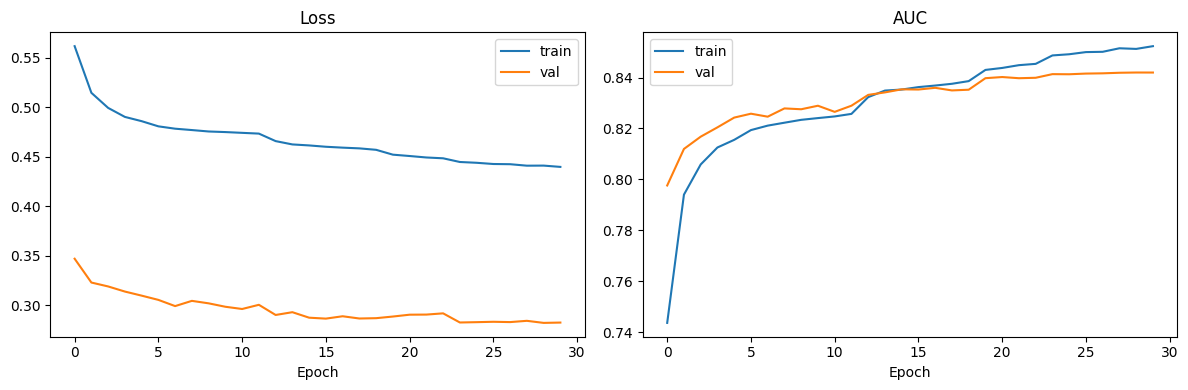

In [30]:
plot_res(history)

In [ ]:
final_metrics = np.array([
    history.history['val_accuracy'][-1],
    history.history['val_auc'][-1],
    history.history['val_avg_precision'][-1]
])

results.loc['Keras Best'] = final_metrics

In [31]:
final_model.save('data/final_model.keras')

## Results

In [ ]:
results

,Accuracy,ROC-AUC,Avg Precis
Keras Baseline,0.809159,0.830534,0.301061
Keras Feature Selected,0.820293,0.839975,0.315411
Keras Best,0.888468,0.840645,0.317529
Naive Bayes (Baseline),0.918565,0.500000,0.081435
Random Forest (Baseline),0.919494,0.834838,0.322340
Random Forest (Baseline) CV,0.919440,0.835989,0.326740
Random Forest (Baseline) CV Best,0.919288,0.837178,0.326998
Sklearn MLP,0.917931,0.776493,0.242852
Sklearn MLP CV Best,0.918565,0.478604,0.081458


In [ ]:
results.to_csv('data/results.csv')

## Test

In [32]:
final_model = tf.keras.models.load_model('data/final_model.keras')

In [36]:
set_seed(42)

y_test = final_model.predict(X_test[good_features], verbose=0).ravel()
y_test = pd.Series(y_test, index=test.index)

In [37]:
y_test.to_csv('data/test_res.csv')